In [4]:
import numpy as np
import scipy as sp
import xarray as xr
import seaborn as sea
import matplotlib.pyplot as plt

# Statistical distributions of Norkyst

**Plan:**
- Make distributions for one day for all variables: salinity, temperature, u_speed and v_speed
- A years average + seasonal variations for NK

In [ ]:
#check if code from summer project is adaptable for this use case
sea.set_theme(style="darkgrid")
def histograms(ds, time_to_check = 1, save_path = 'figures/histogram.png'):
    """
    Definition: 

    Arguments:
    arg[1] : dataset - the inference dataset 
    arg[2] : time to check (int) - the timestep in the data would you like the check the variable distribution for

    Outputs: 
    Figure of the variable distributions 
    """

    variables = ['temperature', 'zeta', 'salinity', 'u_eastward', 'v_northward']
    data = {var : ds[var].isel(time = time_to_check).values.ravel() for var in variables}
    data = {var : values[~np.isnan(values)] for var, values in data.items()}

    fig, ax = plt.subplots(2,3, figsize = (12,12), layout = 'compressed')
    titles = ['Temperature', 'zeta', 'Salinity', 'U-Eastward', 'V-Northward']
    
    for i, (var, values) in enumerate(data.items()):
        row, col = divmod(i,3)
        sea.histplot(values, bins = 30, kde = True, ax = ax[row, col], stat='density', color = 'royalblue', edgecolor = 'darkolivegreen')
        ax[row, col].set_title(titles[i], fontsize = 15)
        ax[row, col].set_facecolor("#C4C6D5")
        ax[1,2].axis('off')

    plt.suptitle(f'Histogram & Density curve for Havbris variables')
    plt.tight_layout()
    fig.savefig(save_path)

In [25]:
norkyst_gen_path = '/lustre/storeB/project/fou/hi/foccus/datasets/symlinks/norkystv3-hindcast/2024'
checkpoint_3003 = 'norkyst800-20240330.nc'
ds = xr.open_dataset(f'{norkyst_gen_path}/{checkpoint_3003}').isel(s_rho = -1, s_w = -1)
ds_3003 = ds.resample(time = 'D').mean()

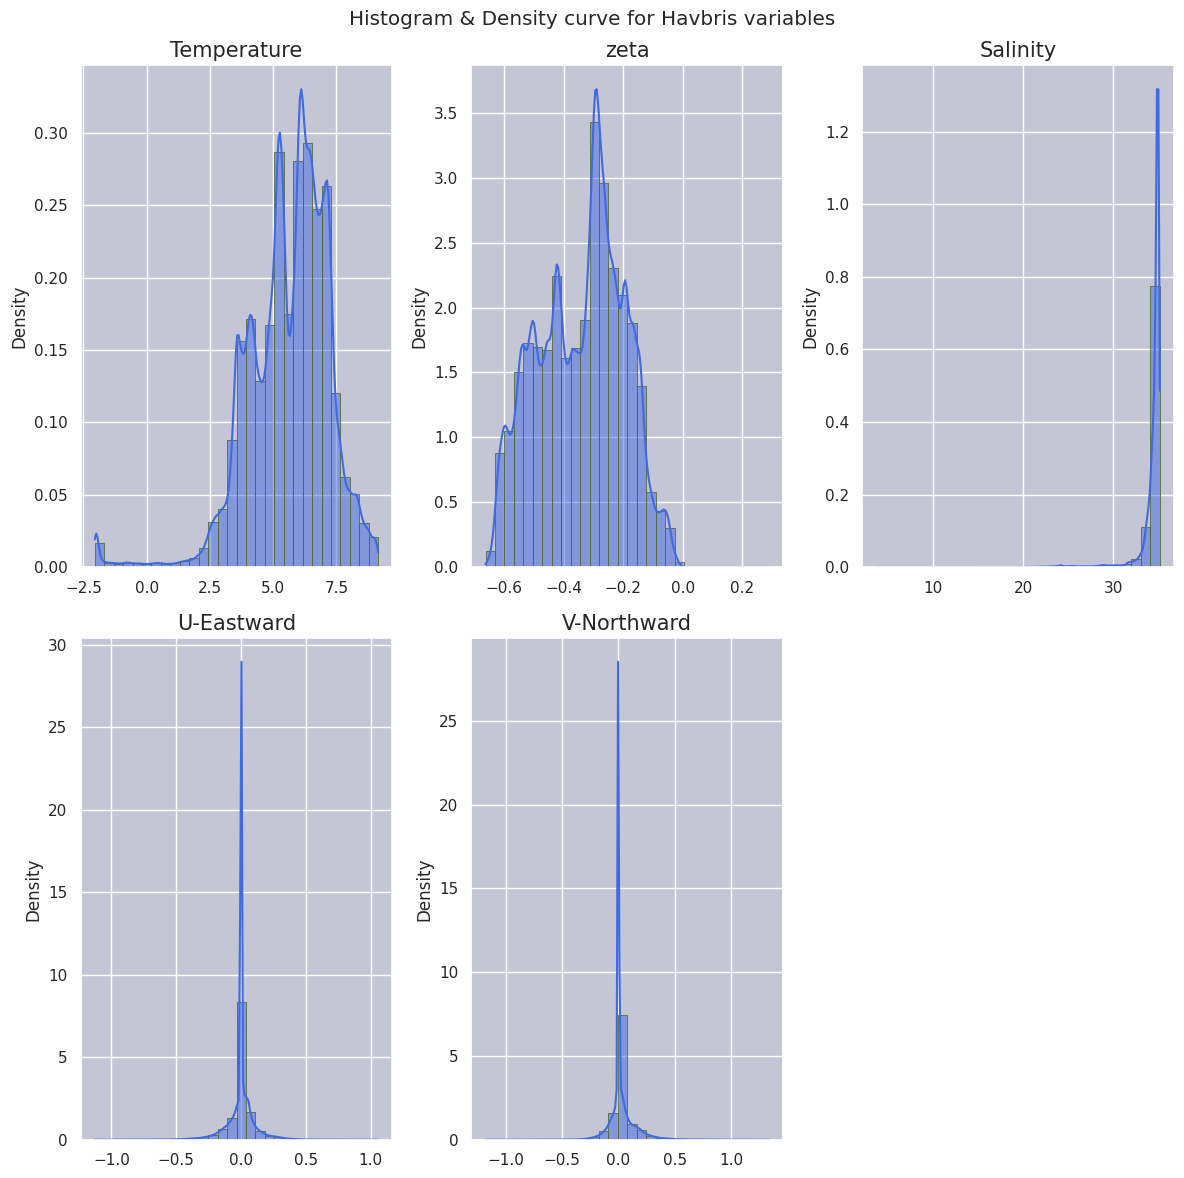

In [38]:
histograms(ds_3003, time_to_check=0, save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/histogramsNK3003.png')

Explanation:

Used resample technique of calculating the mean of the dataset, such that the mean value for each variable is represented in the histogram. 

I have used gridspec to make the plot more visually appealing

Rest is straight forward plotting

In [51]:
#check if code from summer project is adaptable for this use case
sea.set_theme(style="darkgrid")
def histograms_with_specified_layout(ds, time_to_check = 1, save_path = 'figures/histogram.png'):
    """
    Definition: 

    Arguments:
    arg[1] : dataset - the inference dataset 
    arg[2] : time to check (int) - the timestep in the data would you like the check the variable distribution for

    Outputs: 
    Figure of the variable distributions 
    """

    variables = ['salinity', 'u_eastward', 'v_northward', 'temperature', 'zeta']
    data = {var : ds[var].isel(time = time_to_check).values.ravel() for var in variables}
    data = {var : values[~np.isnan(values)] for var, values in data.items()}

    fig = plt.figure(figsize = (12,7))
    titles = ['Salinity', 'U-Eastward', 'V-Northward', 'temperature', 'zeta']
    """ 
    Trying to make the plot more visually appealing witg gridspec, to elongate the bottom plots.
    """
    gs = fig.add_gridspec(2,6)
    axes = [fig.add_subplot(gs[0,0:2]), fig.add_subplot(gs[0,2:4]), fig.add_subplot(gs[0,4:6]), fig.add_subplot(gs[1,0:3]), fig.add_subplot(gs[1,3:6])]
    
    for i, (var, values) in enumerate(data.items()):
        row, col = divmod(i,3)
        sea.histplot(values, bins = 30, kde = True, ax = axes[i], stat='density', color = 'royalblue', edgecolor = 'darkolivegreen')
        axes[i].set_title(titles[i], fontsize = 15)
        axes[i].set_facecolor("#C4C6D5")
        #axes[1,2].axis('off')

    plt.suptitle(f'Histogram & Density curve for Norkyst variables')
    plt.tight_layout()
    fig.savefig(save_path)

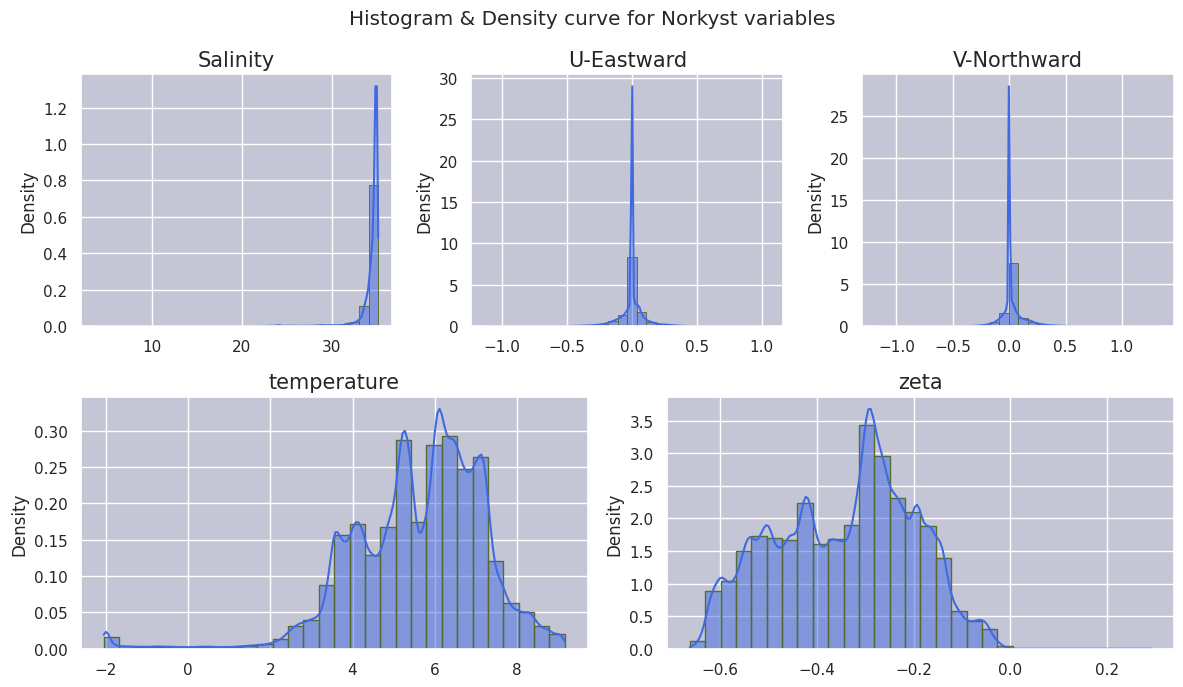

In [52]:
histograms_with_specified_layout(ds_3003, time_to_check=0, save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/histogramsNK3003.png')

In [ ]:
#Repeat for a Havbris - will use an already existing file and thus repeat for Norkyst as well with the same date
hb = '/lustre/storeB/project/fou/hi/foccus/experiments/rollout-benchmark/'
#gen path /lustre/storeB/project/fou/hi/foccus/experiments/rollout-benchmark/lr3.5e6-rs3-i0-m3/checkpoint/aa8859acb07a4d23a8b65eb2997064d0
